# Clustering V3

For this last clustering experiment, I wanted to see whether standardizing the features or changing the starting centroids would affect the results. I used the same 1000 sentiment samples as before.

First, I imported the libraries and functions I'll need.

In [1]:
from pathlib import Path
from time import perf_counter
from collections import Counter
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd()
if not (project_root / "src").is_dir():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from src.data_loader import load_task
from src.models.clustering import KMeans


I started by selecting the same 1000 sentiment samples as in V1 and V2.

In [2]:
X_train, y_train, _, _ = load_task("sentiment")
assert X_train.shape == (12000, 768)
rng = np.random.default_rng(42)
indices = rng.choice(len(X_train), size=1000, replace=False)
X_subset = X_train[indices]
y_subset = y_train[indices]
assert len(np.unique(indices)) == 1000
result_dir = project_root / "results" / "clustering"
v1_assignments = pd.read_csv(result_dir / "clustering_v1_assignments.csv")
v1_summary = pd.read_csv(result_dir / "clustering_v1_summary.csv").iloc[0]
v1_counts = pd.read_csv(result_dir / "clustering_v1_cluster_counts.csv")
assert indices.tolist() == v1_assignments["original_row_index"].tolist()
assert y_subset.tolist() == v1_assignments["true_label"].tolist()
print("The selected row indices and true labels match V1 exactly.")


The selected row indices and true labels match V1 exactly.


Then I compared k-Means with the original and standardized features.

In [3]:
def standardize(X):
    X = np.asarray(X, dtype=float)
    means = np.mean(X, axis=0)
    stds = np.std(X, axis=0)
    return (X - means) / (stds + 1e-8), means, stds

X_standardized, means, stds = standardize(X_subset)
scaling_models = {}
scaling_times = {}
for normalized, features in [(False, X_subset), (True, X_standardized)]:
    km = KMeans(k=3, max_iter=100, tol=1e-4, seed=42)
    start = perf_counter()
    km.fit(features)
    fit_time = perf_counter() - start
    scaling_models[normalized] = km
    scaling_times[normalized] = fit_time
    cluster_sizes = Counter(km.labels_)
    print(f"Normalized={normalized}, samples={len(features)}, features={features.shape[1]}, k={km.k}, seed={km.seed}")
    print(f"Iterations={km.n_iter_}, inertia={km.inertia_:.6f}, fit time={fit_time:.6f} s")
    print("Cluster sizes:", [cluster_sizes[cluster] for cluster in range(km.k)])


Normalized=False, samples=1000, features=768, k=3, seed=42
Iterations=19, inertia=26325.122315, fit time=0.695077 s
Cluster sizes: [400, 266, 334]
Normalized=True, samples=1000, features=768, k=3, seed=42
Iterations=36, inertia=717839.121211, fit time=1.255243 s
Cluster sizes: [429, 118, 453]


I compared the clusters with the actual sentiment labels.

In [4]:
def cluster_purity(labels_pred, labels_true):
    correct = 0
    for cluster_id in set(labels_pred):
        true_in_cluster = [labels_true[i] for i in range(len(labels_pred))
                           if labels_pred[i] == cluster_id]
        correct += Counter(true_in_cluster).most_common(1)[0][1]
    return correct / len(labels_pred)

scaling_rows = []
count_rows = []
for normalized, km in scaling_models.items():
    purity = cluster_purity(km.labels_, y_subset)
    scaling_rows.append({
        "version": "V3",
        "dataset": "sentiment",
        "samples": len(X_subset),
        "features": X_subset.shape[1],
        "k": km.k,
        "seed": km.seed,
        "max_iter": km.max_iter,
        "normalized": normalized,
        "iterations": km.n_iter_,
        "inertia": km.inertia_,
        "purity": purity,
        "fit_time_seconds": scaling_times[normalized],
    })
    for cluster in range(km.k):
        true_in_cluster = [y_subset[i] for i in range(len(y_subset))
                           if km.labels_[i] == cluster]
        counts = Counter(true_in_cluster)
        count_rows.append({
            "normalized": normalized,
            "cluster": cluster,
            "negative": counts[0],
            "neutral": counts[1],
            "positive": counts[2],
            "total": len(true_in_cluster),
        })
scaling_summary = pd.DataFrame(scaling_rows)
cluster_counts = pd.DataFrame(count_rows)
original_model = scaling_models[False]
assert original_model.labels_.tolist() == v1_assignments["cluster"].tolist()
assert original_model.n_iter_ == v1_summary["iterations"] == 19
assert np.isclose(original_model.inertia_, v1_summary["inertia"], rtol=1e-12, atol=1e-8)
assert scaling_summary.loc[0, "purity"] == v1_summary["purity"] == 0.387
for column in ["cluster", "negative", "neutral", "positive", "total"]:
    assert cluster_counts.loc[
        cluster_counts["normalized"] == False, column
    ].tolist() == v1_counts[column].tolist()
for normalized in [False, True]:
    counts = cluster_counts.loc[cluster_counts["normalized"] == normalized]
    assert counts["total"].sum() == 1000
    assert counts[["negative", "neutral", "positive"]].to_numpy().sum() == 1000
print("Original features reproduce V1 exactly.")
print("Cluster IDs are arbitrary, not sentiment classes.")
print(cluster_counts.to_string(index=False))
print(f"Original purity: {scaling_summary.loc[0, 'purity']:.3f}")
print(f"Standardized purity: {scaling_summary.loc[1, 'purity']:.3f}")
print("Purity changed:", scaling_summary.loc[0, "purity"] != scaling_summary.loc[1, "purity"])
print("Cluster ID arrays identical after scaling:", np.array_equal(original_model.labels_, scaling_models[True].labels_))
print("Original and standardized inertia values use different scales and are not directly comparable.")


Original features reproduce V1 exactly.
Cluster IDs are arbitrary, not sentiment classes.
 normalized  cluster  negative  neutral  positive  total
      False        0       122      134       144    400
      False        1        81      123        62    266
      False        2       114      100       120    334
       True        0       126      150       153    429
       True        1        26       59        33    118
       True        2       165      148       140    453
Original purity: 0.387
Standardized purity: 0.377
Purity changed: True
Cluster ID arrays identical after scaling: False
Original and standardized inertia values use different scales and are not directly comparable.


I plotted the purity values to compare both versions.

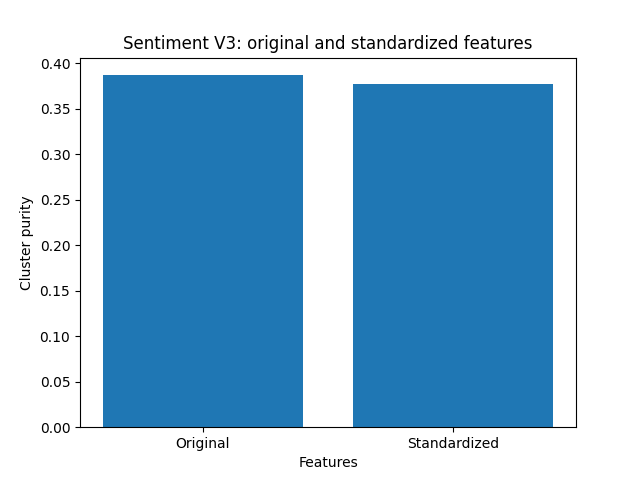

In [5]:
plt.figure()
plt.bar(["Original", "Standardized"], scaling_summary["purity"])
plt.xlabel("Features")
plt.ylabel("Cluster purity")
plt.title("Sentiment V3: original and standardized features")
plt.savefig(result_dir / "clustering_v3_scaling_purity.png")
plt.show()


Next, I tried different random seeds to see if the results would change.

In [6]:
seeds = [0, 1, 2, 3, 4, 5, 6, 7, 42]
seed_rows = []
seed_models = {}
for seed in seeds:
    km = KMeans(k=3, max_iter=100, tol=1e-4, seed=seed)
    start = perf_counter()
    km.fit(X_subset)
    fit_time = perf_counter() - start
    seed_models[seed] = km
    purity = cluster_purity(km.labels_, y_subset)
    seed_rows.append({
        "version": "V3",
        "dataset": "sentiment",
        "samples": len(X_subset),
        "features": X_subset.shape[1],
        "k": km.k,
        "seed": seed,
        "max_iter": km.max_iter,
        "normalized": False,
        "iterations": km.n_iter_,
        "inertia": km.inertia_,
        "purity": purity,
        "fit_time_seconds": fit_time,
    })
    print(f"Seed={seed:2d}, iterations={km.n_iter_}, inertia={km.inertia_:.6f}, purity={purity:.3f}, fit time={fit_time:.6f} s")
    if seed == 42:
        assert km.labels_.tolist() == v1_assignments["cluster"].tolist()
        assert km.n_iter_ == v1_summary["iterations"] == 19
        assert np.isclose(km.inertia_, v1_summary["inertia"], rtol=1e-12, atol=1e-8)
        assert purity == v1_summary["purity"] == 0.387
        assert [int((km.labels_ == cluster).sum()) for cluster in range(3)] == v1_counts["total"].tolist()
        print("Seed 42 reproduces V1 exactly.")
seeds_summary = pd.DataFrame(seed_rows)
print("Inertia changed between seeds:", len(set(seeds_summary["inertia"])) > 1)
print("Purity changed between seeds:", len(set(seeds_summary["purity"])) > 1)
print("Iterations changed between seeds:", len(set(seeds_summary["iterations"])) > 1)


Seed= 0, iterations=23, inertia=26321.999707, purity=0.388, fit time=0.803622 s
Seed= 1, iterations=13, inertia=26467.321139, purity=0.377, fit time=0.461030 s
Seed= 2, iterations=14, inertia=27051.197532, purity=0.371, fit time=0.416624 s
Seed= 3, iterations=11, inertia=26492.798128, purity=0.380, fit time=0.429744 s
Seed= 4, iterations=12, inertia=26322.834236, purity=0.387, fit time=0.503343 s
Seed= 5, iterations=29, inertia=26460.698805, purity=0.388, fit time=0.764942 s
Seed= 6, iterations=16, inertia=26328.355871, purity=0.389, fit time=0.446674 s
Seed= 7, iterations=10, inertia=26322.074685, purity=0.383, fit time=0.484437 s
Seed=42, iterations=19, inertia=26325.122315, purity=0.387, fit time=0.497379 s
Seed 42 reproduces V1 exactly.
Inertia changed between seeds: True
Purity changed between seeds: True
Iterations changed between seeds: True


I plotted the inertia values for each seed.

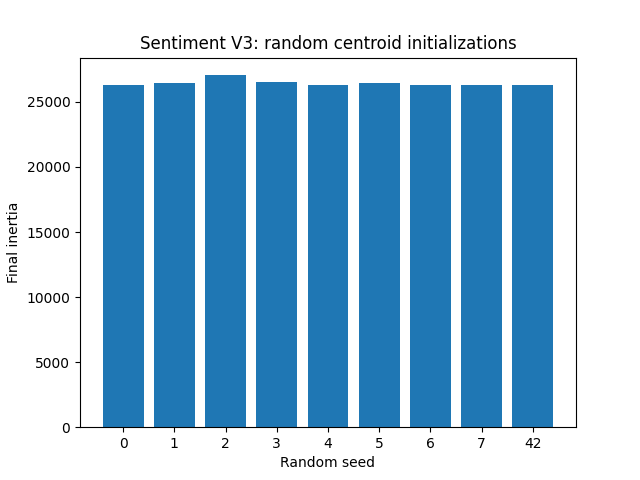

In [7]:
plt.figure()
plt.bar([str(seed) for seed in seeds_summary["seed"]], seeds_summary["inertia"])
plt.xlabel("Random seed")
plt.ylabel("Final inertia")
plt.title("Sentiment V3: random centroid initializations")
plt.savefig(result_dir / "clustering_v3_seeds_inertia.png")
plt.show()


Finally, I saved the results from both experiments.

In [8]:
assert len(scaling_summary) == 2 and len(cluster_counts) == 6
assert len(seeds_summary) == 9
assert seeds_summary["seed"].tolist() == seeds
scaling_summary.to_csv(result_dir / "clustering_v3_scaling_summary.csv", index=False)
cluster_counts.to_csv(result_dir / "clustering_v3_cluster_counts.csv", index=False)
seeds_summary.to_csv(result_dir / "clustering_v3_seeds_summary.csv", index=False)
print(scaling_summary.to_string(index=False))
print(seeds_summary.to_string(index=False))
print("Saved both experiments and graphs in", result_dir)


version   dataset  samples  features  k  seed  max_iter  normalized  iterations       inertia  purity  fit_time_seconds
     V3 sentiment     1000       768  3    42       100       False          19  26325.122315   0.387          0.695077
     V3 sentiment     1000       768  3    42       100        True          36 717839.121211   0.377          1.255243
version   dataset  samples  features  k  seed  max_iter  normalized  iterations      inertia  purity  fit_time_seconds
     V3 sentiment     1000       768  3     0       100       False          23 26321.999707   0.388          0.803622
     V3 sentiment     1000       768  3     1       100       False          13 26467.321139   0.377          0.461030
     V3 sentiment     1000       768  3     2       100       False          14 27051.197532   0.371          0.416624
     V3 sentiment     1000       768  3     3       100       False          11 26492.798128   0.380          0.429744
     V3 sentiment     1000       768  3     4